In [20]:
import pandas as pd
import numpy as np
import seaborn as sns 

In [21]:
df_copy = pd.read_csv('cookie_cats.csv')
df = df_copy.copy()

In [22]:
df['userid'].duplicated().sum()

np.int64(0)

In [23]:
df['version'].value_counts()

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [24]:
df.isna().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

<Axes: ylabel='sum_gamerounds'>

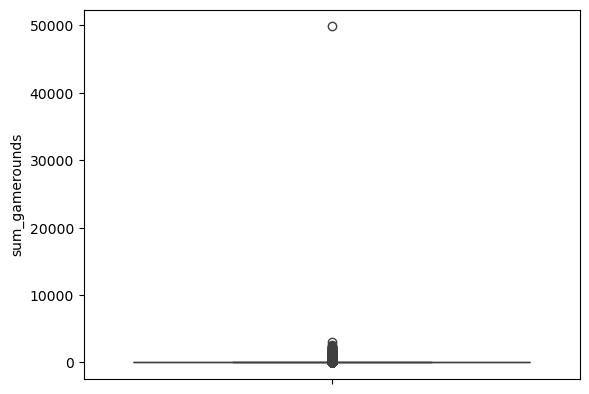

In [25]:
sns.boxplot(data=df['sum_gamerounds'])

In [ ]:
df['sum_gamerounds'].quantile(0.99)

np.float64(493.0)

In [27]:
max = df['sum_gamerounds'].quantile(0.999)
df = df[df['sum_gamerounds'] < max]

<Axes: ylabel='sum_gamerounds'>

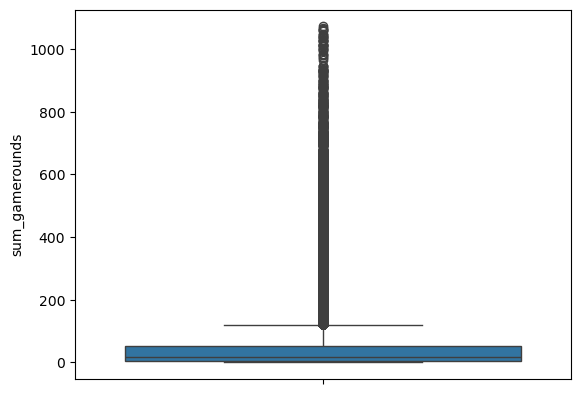

In [28]:
sns.boxplot(data=df['sum_gamerounds'])

In [29]:
df.groupby('version').agg({
    'userid': 'count',
    'sum_gamerounds':['mean', 'median'],
    'retention_1': ['sum', 'mean'],
    'retention_7' : ['sum', 'mean']
})

userid sum_gamerounds        retention_1           retention_7  \
         count           mean median         sum      mean         sum   
version                                                                  
gate_30  44659      50.092098   17.0       19994  0.447704        8461   
gate_40  45439      49.809921   16.0       20071  0.441713        8231   

                   
             mean  
version            
gate_30  0.189458  
gate_40  0.181144

In [30]:
from scipy.stats import chi2_contingency

tab_1 = pd.crosstab(df['version'], df['retention_1'])
chi2_1, p_val_1, _, _ = chi2_contingency(tab_1)
print(p_val_1)

0.07146578682058832


In [31]:
tab_7 = pd.crosstab(df['version'], df['retention_7'])
chi2_7, p_val_7, _, _ = chi2_contingency(tab_7)
print(p_val_7)

0.001360204189027744


<Axes: xlabel='sum_gamerounds', ylabel='Count'>

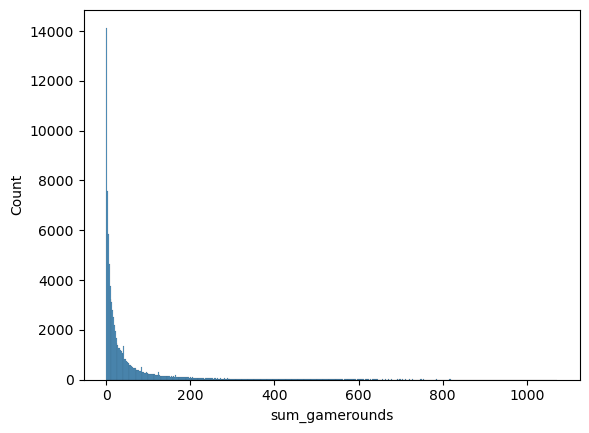

In [32]:
sns.histplot(data=df['sum_gamerounds'])

In [33]:
n_bootstrap = 10000

boot_gate_30 = []
boot_gate_40 = []

gate_30_rounds = df[df['version'] == 'gate_30']['sum_gamerounds'].values
gate_40_rounds = df[df['version'] == 'gate_40']['sum_gamerounds'].values

In [34]:
for i in range(n_bootstrap):
    boot_30 = np.random.choice(gate_30_rounds, size=len(gate_30_rounds), replace=True)
    boot_40 = np.random.choice(gate_40_rounds, size=len(gate_40_rounds), replace=True)

    boot_gate_30.append(boot_30.mean())
    boot_gate_40.append(boot_40.mean())

In [35]:
boot_diff = pd.DataFrame({'diff':np.array(boot_gate_30) - np.array(boot_gate_40)})

<Axes: ylabel='Count'>

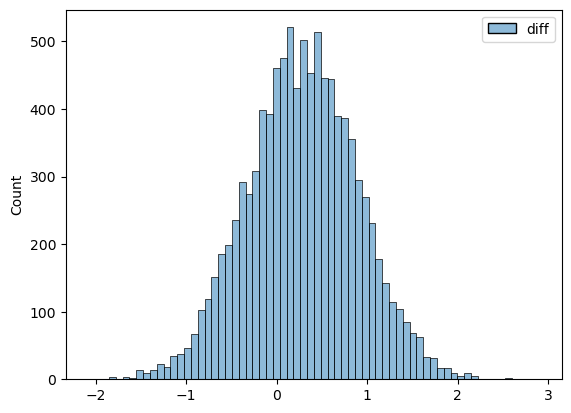

In [36]:
sns.histplot(data=boot_diff)

In [37]:
lower = boot_diff['diff'].quantile(0.025)
upper = boot_diff['diff'].quantile(0.975)


In [38]:
print(lower, upper)

-0.9010567340222128 1.4908732028779779
